In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             RocCurveDisplay, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_recall_curve, average_precision_score)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 100)
print('Environment ready')

Environment ready


In [4]:
CHURN_CSV = 'ecommerce_churn.csv'  # change to your CSV path
CHURN_TARGET = 'churn'              # change to your target column

if os.path.exists(CHURN_CSV):
    churn_df = pd.read_csv(CHURN_CSV)
    print('Loaded real CSV:', CHURN_CSV)
else:
    rng = np.random.default_rng(SEED)
    n = 5000
    churn_df = pd.DataFrame({
        'recency_days': rng.integers(0, 180, n),
        'orders_90d': rng.poisson(4, n),
        'avg_order_value': rng.normal(75, 25, n).clip(5, 300),
        'sessions_30d': rng.poisson(8, n),
        'support_tickets': rng.poisson(1, n),
        'returns_90d': rng.poisson(0.5, n),
        'tenure_months': rng.integers(1, 72, n),
        'membership_tier': rng.choice(['Basic','Silver','Gold'], n, p=[.55,.3,.15]),
        'acquisition_channel': rng.choice(['Ads','Organic','Referral','Email'], n)
    })
    logit = -1.1 + .018*churn_df.recency_days - .22*churn_df.orders_90d - .025*churn_df.sessions_30d + .35*churn_df.support_tickets + .3*churn_df.returns_90d - .012*churn_df.tenure_months
    prob = 1/(1+np.exp(-logit))
    churn_df['churn'] = rng.binomial(1, prob)
    print('Demo synthetic data created because CSV was not found.')

print('Shape:', churn_df.shape)
display(churn_df.head())
print(churn_df.isna().sum().sort_values(ascending=False).head(10))

Demo synthetic data created because CSV was not found.
Shape: (5000, 10)


,recency_days,orders_90d,avg_order_value,sessions_30d,support_tickets,returns_90d,tenure_months,membership_tier,acquisition_channel,churn
0,16,3,57.137772,6,0,0,17,Basic,Ads,0
1,139,1,23.733180,9,3,0,8,Basic,Referral,1
2,117,6,131.311074,8,1,1,28,Basic,Organic,1
3,78,3,69.214266,8,1,0,42,Basic,Email,0
4,77,3,111.176447,5,1,0,54,Gold,Email,0


recency_days           0
orders_90d             0
avg_order_value        0
sessions_30d           0
support_tickets        0
returns_90d            0
tenure_months          0
membership_tier        0
acquisition_channel    0
churn                  0
dtype: int64


In [5]:
# Update CHURN_TARGET if your real dataset uses a different target name.
if CHURN_TARGET not in churn_df.columns:
    raise ValueError(f'Target {CHURN_TARGET!r} not found. Available columns: {churn_df.columns.tolist()}')

# Remove obvious ID columns if present; identifiers usually do not generalize.
X = churn_df.drop(columns=[CHURN_TARGET]).copy()
y = churn_df[CHURN_TARGET].copy()
# Convert common text labels to binary if needed; otherwise target must be numeric/binary.
if y.dtype == 'object':
    vals = list(pd.Series(y.dropna().unique()).astype(str))
    if len(vals) == 2:
        y = y.astype(str).map({vals[0]: 0, vals[1]: 1})
    else:
        raise ValueError('Churn target must be binary. Map your labels to 0/1 first.')
y = pd.to_numeric(y, errors='coerce')
valid = y.notna()
X, y = X.loc[valid], y.loc[valid].astype(int)
# Drop high-cardinality IDs based on column names
id_cols = [c for c in X.columns if c.lower() in ['customer_id','user_id','id','account_id']]
X = X.drop(columns=id_cols, errors='ignore')
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
pre = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=SEED, n_jobs=-1)
}
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
results = []
for name, estimator in models.items():
    pipe = Pipeline([('preprocess', pre), ('model', estimator)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='roc_auc', n_jobs=-1)
    results.append((name, scores.mean(), scores.std()))
results_df = pd.DataFrame(results, columns=['model','cv_roc_auc_mean','cv_roc_auc_std']).sort_values('cv_roc_auc_mean', ascending=False)
display(results_df)

,model,cv_roc_auc_mean,cv_roc_auc_std
0,Logistic Regression,0.779583,0.017836
1,Random Forest,0.760002,0.016717
2,Extra Trees,0.754539,0.015163


Selected: Logistic Regression
Test ROC-AUC: 0.7906
              precision    recall  f1-score   support

           0       0.80      0.71      0.75       597
           1       0.63      0.74      0.68       403

    accuracy                           0.72      1000
   macro avg       0.72      0.72      0.72      1000
weighted avg       0.73      0.72      0.72      1000



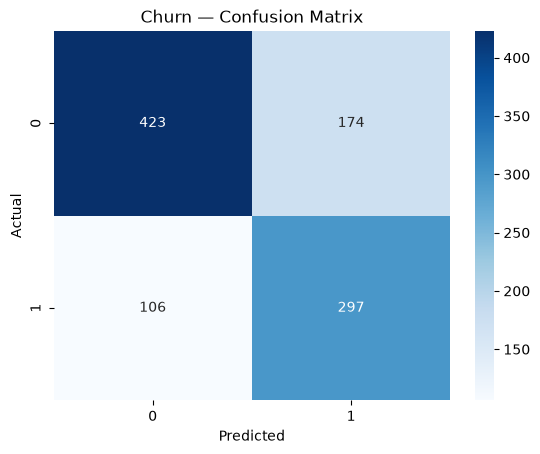

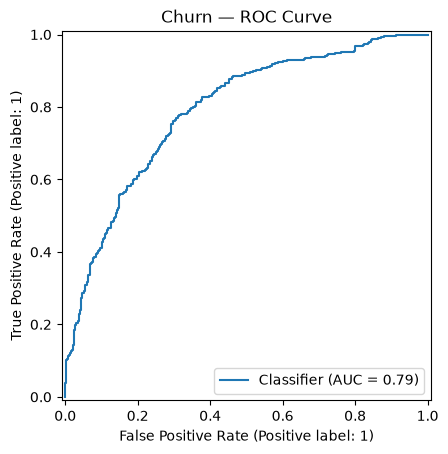

,recency_days,orders_90d,avg_order_value,sessions_30d,support_tickets,returns_90d,tenure_months,membership_tier,acquisition_channel,churn,churn_probability,risk_segment
3354,175,0,115.074005,6,3,1,7,Basic,Email,1,0.980908,High
45,174,4,57.654861,8,3,2,3,Basic,Email,1,0.964244,High
4542,166,3,75.141408,11,5,1,42,Basic,Email,1,0.951725,High
4849,162,5,93.694724,6,5,0,4,Basic,Email,1,0.950071,High
4549,156,1,75.723182,7,2,1,3,Silver,Email,1,0.945928,High
1087,178,2,56.584683,4,0,2,11,Basic,Referral,1,0.942476,High
1796,175,1,70.227535,4,2,1,40,Gold,Ads,1,0.938909,High
201,163,3,93.068776,14,4,0,4,Basic,Organic,1,0.936395,High
641,164,4,81.240560,5,2,2,14,Basic,Email,1,0.936069,High
140,176,1,68.187843,11,1,0,2,Basic,Referral,1,0.932138,High


Saved churn_test_scored.csv and churn_model.joblib


   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   - -----------------------------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'c:\\users\\short\\appdata\\local\\programs\\python\\python313\\lib\\site-packages\\matplotlib\\backends\\_backend_agg.cp313-win_amd64.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
best_name = results_df.iloc[0]['model']
churn_model = Pipeline([('preprocess', pre), ('model', models[best_name])])
churn_model.fit(X_train, y_train)
proba = churn_model.predict_proba(X_test)[:, 1]
pred = (proba >= .5).astype(int)
print('Selected:', best_name)
print('Test ROC-AUC:', round(roc_auc_score(y_test, proba), 4))
print(classification_report(y_test, pred, zero_division=0))
ConfusionMatrixDisplay = None
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues')
plt.title('Churn — Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()
RocCurveDisplay.from_predictions(y_test, proba); plt.title('Churn — ROC Curve'); plt.show()
churn_scored = churn_df.loc[X_test.index].copy()
churn_scored['churn_probability'] = proba
churn_scored['risk_segment'] = pd.cut(proba, bins=[-0.001,.3,.6,1.001], labels=['Low','Medium','High'])
display(churn_scored.sort_values('churn_probability', ascending=False).head(15))
churn_scored.to_csv('churn_test_scored.csv', index=False)
joblib.dump(churn_model, 'churn_model.joblib')
print('Saved churn_test_scored.csv and churn_model.joblib')